<a href="https://colab.research.google.com/github/piihutanoch/pet-breed-classifier/blob/main/02_baseline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import json, sys, time
import torch

project_dir= Path("/content/drive/MyDrive/pet-breed-classifier")
artifacts_dir= project_dir/"artifacts"
src_dir= project_dir/"src"            # reusable .py files live here
data_dir= Path("/content/data")

src_dir.mkdir(parents=True, exist_ok= True)
data_dir.mkdir(parents=True, exist_ok= True)

seed= 42
torch.manual_seed(seed)                  # makes PyTorch's randomness repeatable

device= "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)                 # must print: cuda

Mounted at /content/drive
device: cuda


### Setup
- Same Drive and folder setup as Day 1, plus `src_dir` for reusable code files.
- `torch.manual_seed(seed)` fixes PyTorch's randomness (e.g. the random starting weights of the new layer), so runs are repeatable.
- **`device`**: `"cuda"` = GPU, `"cpu"` = CPU. The GPU makes training 10–50× faster.
- **Rule:** the model and the data must be on the same device → `.to(device)`.

In [2]:
!wget -q --show-progress https://s3.amazonaws.com/fast-ai-imageclas/oxford-iiit-pet.tgz -O /content/pets.tgz
!tar -xzf /content/pets.tgz -C /content/data
!ls /content/data/oxford-iiit-pet

/content/pets.tgz   100%[===================>] 774.10M  17.9MB/s    in 46s     
annotations  images


In [3]:
with open(artifacts_dir/"splits.json") as f:
    splits= json.load(f)
train_idx= splits["train"]
val_idx= splits["val"]

with open(artifacts_dir/"classes.json") as f:
    idx_to_class= json.load(f)

print("train:", len(train_idx), "val:", len(val_idx))   # 3128, 552
print("class 0:", idx_to_class["0"])                     # JSON keys are strings

train: 3128 val: 552
class 0: Abyssinian


In [4]:
%%writefile /content/drive/MyDrive/pet-breed-classifier/src/data.py
from torchvision import transforms
from torchvision.datasets import OxfordIIITPet
from torch.utils.data import Subset, DataLoader

# ImageNet's per-channel (R, G, B) mean and std: the stats the pretrained model was trained with
IMAGENET_MEAN= [0.485, 0.456, 0.406]
IMAGENET_STD= [0.229, 0.224, 0.225]


def get_eval_transform():
    """Preprocessing for val, test and the app: exactly what the pretrained model expects."""
    return transforms.Compose([
        transforms.Resize(256),             # shorter side -> 256, keeps aspect ratio
        transforms.CenterCrop(224),         # central 224x224 square
        transforms.ToTensor(),              # PIL -> tensor (3, 224, 224), values 0..1
        transforms.Normalize(mean= IMAGENET_MEAN, std= IMAGENET_STD),   # (x - mean) / std
    ])


def get_train_transform():
    return get_eval_transform()


def get_loaders(data_dir, train_idx, val_idx, batch_size=32):
    # Two dataset objects over the same files, each with its own transform
    train_base= OxfordIIITPet(root=data_dir, split="trainval",
                               target_types="category", transform=get_train_transform())
    val_base= OxfordIIITPet(root=data_dir, split="trainval",
                             target_types="category", transform=get_eval_transform())

    # Keep only the positions from Day 1's saved split
    train_ds= Subset(train_base, train_idx)
    val_ds= Subset(val_base, val_idx)

    train_loader= DataLoader(train_ds, batch_size=batch_size, shuffle=True, num_workers=2)
    val_loader= DataLoader(val_ds, batch_size=batch_size, shuffle=False, num_workers=2)  # order doesn't matter for scoring
    return train_loader, val_loader

Writing /content/drive/MyDrive/pet-breed-classifier/src/data.py


### src/data.py: data pipeline
- `%%writefile` **saves** this cell as a file (it doesn't run it). Code lives in `src/` so notebooks and the app share one copy.
- **Pretrained preprocessing** (must match how EfficientNet was trained on ImageNet):
  1. `Resize(256)`: shorter side → 256, aspect ratio kept (no squashing)
  2. `CenterCrop(224)`: central 224×224
  3. `ToTensor()`: shape (3, 224, 224), values 0–1
  4. `Normalize`: `(x − mean) / std` per channel with ImageNet stats → values roughly −2 to +2
- Like reusing a fitted `StandardScaler`: same preprocessing at training and prediction time.
- Separate train/val datasets: identical today; Wednesday only train gets augmentation.
- `shuffle=True` for train (new order each epoch), `False` for val (order doesn't change accuracy).
- torchvision's `OxfordIIITPet` already converts every image to RGB.

In [6]:
import importlib
sys.path.append(str(project_dir))   # lets Python find the "src" folder

import src.data
importlib.reload(src.data)          # picks up the latest version of data.py if you edited it
from src.data import get_loaders

train_loader, val_loader = get_loaders(data_dir, train_idx, val_idx, batch_size=32)

images, labels = next(iter(train_loader))
print("batch shape:", images.shape)                       # (32, 3, 224, 224)
print("min:", round(images.min().item(), 2), " max:", round(images.max().item(), 2))
print("mean:", round(images.mean().item(), 2))            # near 0 after Normalize

# Compare with the preprocessing torchvision officially ships with these weights
from torchvision.models import EfficientNet_B0_Weights
print(EfficientNet_B0_Weights.DEFAULT.transforms())

batch shape: torch.Size([32, 3, 224, 224])
min: -2.12  max: 2.64
mean: 0.06
ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BICUBIC
)


In [7]:
%%writefile /content/drive/MyDrive/pet-breed-classifier/src/model.py
import torch.nn as nn
from torchvision import models


def build_model(name="efficientnet_b0", num_classes=37, freeze=True):
    if name == "efficientnet_b0":
        # Download EfficientNet-B0 with its ImageNet-pretrained weights
        model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT)

        # 1) Freeze every pretrained weight (used, but never updated)
        if freeze:
            for param in model.parameters():
                param.requires_grad = False

        # 2) Replace the 1000-class head with a new 37-class one.
        #    A new layer has requires_grad=True by default, so it trains.
        in_features = model.classifier[1].in_features      # 1280
        model.classifier[1] = nn.Linear(in_features, num_classes)
    else:
        raise ValueError(f"Unknown model name: {name}")   # ResNet-50 added Wednesday

    return model

Writing /content/drive/MyDrive/pet-breed-classifier/src/model.py


In [8]:
import src.model
importlib.reload(src.model)         # picks up the latest version of model.py
from src.model import build_model


model = build_model("efficientnet_b0", num_classes=37, freeze=True)
model = model.to(device)               # move all weights to the GPU

print(model.classifier)

total = sum(p.numel() for p in model.parameters())
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"total params:     {total:,}")       # ~4.05 million
print(f"trainable params: {trainable:,}")   # 1280*37 + 37 = 47,397

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 69.7MB/s]


Sequential(
  (0): Dropout(p=0.2, inplace=True)
  (1): Linear(in_features=1280, out_features=37, bias=True)
)
total params:     4,054,945
trainable params: 47,397


### Build the model
- `.to(device)` moves all weights to the GPU.
- Total ≈ 4.05M parameters, but only **47,397 are trainable** (1280×37 weights + 37 biases), about 1%.
- So training only fits the last layer, which is why it's fast.

In [9]:
import torch.nn as nn

def train_one_epoch(model, loader, loss_fn, optimizer, device):
    model.train()                             # dropout ON
    total_loss, correct, count = 0.0, 0, 0

    for images, labels in loader:
        images = images.to(device)            # data must be on the same device as the model
        labels = labels.to(device)

        outputs = model(images)               # forward pass: (batch, 37) logits
        loss = loss_fn(outputs, labels)       # mean loss over the batch

        optimizer.zero_grad()                 # 1) clear old gradients
        loss.backward()                       # 2) compute new gradients
        optimizer.step()                      # 3) update trainable weights

        batch_size = images.size(0)
        total_loss += loss.item() * batch_size          # undo the mean, so totals are exact
        preds = outputs.argmax(dim=1)                   # predicted class per image
        correct += (preds == labels).sum().item()
        count += batch_size

    return total_loss / count, correct / count


def evaluate(model, loader, loss_fn, device):
    model.eval()                              # dropout OFF, deterministic
    total_loss, correct, count = 0.0, 0, 0

    with torch.no_grad():                     # no gradient tracking: faster, less memory
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = loss_fn(outputs, labels)

            batch_size = images.size(0)
            total_loss += loss.item() * batch_size
            preds = outputs.argmax(dim=1)
            correct += (preds == labels).sum().item()
            count += batch_size

    return total_loss / count, correct / count


loss_fn = nn.CrossEntropyLoss()

# Sanity check: the untrained head should be about as good as random guessing
val_loss0, val_acc0 = evaluate(model, val_loader, loss_fn, device)
print(f"before training → val loss {val_loss0:.2f}, val acc {val_acc0:.3f}")
print("random guessing → acc ≈ 0.027, loss ≈ ln(37) = 3.61")

before training → val loss 3.64, val acc 0.014
random guessing → acc ≈ 0.027, loss ≈ ln(37) = 3.61


### Training loop
**One step per batch:** forward → loss → `zero_grad` → `backward` → `step`
- **Logits**: raw scores, shape (batch, 37). `CrossEntropyLoss` = softmax + log loss (same as logistic regression).
- `zero_grad()`: PyTorch *accumulates* gradients, so they must be cleared every step.
- `backward()`: computes gradients. `step()`: updates the weights (Adam).
- **Epoch** = one full pass over the training data.
- `model.train()`: dropout on. `model.eval()`: dropout off, deterministic. `torch.no_grad()`: no gradient tracking during evaluation.
- `argmax(dim=1)`: predicted class per image.
- Loss × batch size, then ÷ total count → an exact average (the last batch has only 24 images).
- **Sanity check:** before training, accuracy ≈ 1/37 and loss ≈ ln(37) ≈ 3.61, i.e. random guessing.

In [10]:
optimizer = torch.optim.Adam(model.classifier.parameters(), lr=1e-3)

num_epochs = 5
history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": [], "epoch_time": []}
best_val_acc = 0.0
ckpt_path = artifacts_dir / "baseline_b0.pt"

for epoch in range(1, num_epochs + 1):
    start = time.time()
    train_loss, train_acc = train_one_epoch(model, train_loader, loss_fn, optimizer, device)
    val_loss, val_acc = evaluate(model, val_loader, loss_fn, device)
    epoch_time = time.time() - start

    # Store everything for the plots and results.md
    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)
    history["epoch_time"].append(epoch_time)

    print(f"Epoch {epoch}/{num_epochs} | "
          f"train loss {train_loss:.3f} acc {train_acc:.3f} | "
          f"val loss {val_loss:.3f} acc {val_acc:.3f} | {epoch_time:.0f}s")

    # Keep only the best model (by validation accuracy)
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), ckpt_path)
        print("new best, checkpoint saved")

print("\nBest val accuracy:", round(best_val_acc, 4))

with open(artifacts_dir / "baseline_history.json", "w") as f:
    json.dump(history, f)

Epoch 1/5 | train loss 2.184 acc 0.590 | val loss 1.152 acc 0.830 | 22s
   ↳ new best, checkpoint saved
Epoch 2/5 | train loss 0.936 acc 0.844 | val loss 0.704 acc 0.875 | 25s
   ↳ new best, checkpoint saved
Epoch 3/5 | train loss 0.660 acc 0.876 | val loss 0.584 acc 0.873 | 22s
Epoch 4/5 | train loss 0.501 acc 0.903 | val loss 0.511 acc 0.870 | 23s
Epoch 5/5 | train loss 0.423 acc 0.916 | val loss 0.497 acc 0.879 | 21s
   ↳ new best, checkpoint saved

Best val accuracy: 0.8786


### Train (frozen baseline)
- Adam, lr = 1e-3, only the head's parameters, 5 epochs, batch 32, no augmentation.
- Each epoch: train on 3,128 images → evaluate on 552 val images → log loss, accuracy and time.
- `state_dict()` = all weights as a dictionary. Saved to Drive **only when val accuracy improves**, so I keep the best epoch.
- History saved to `baseline_history.json` for plots and the README.
- **Result:** best val accuracy = ___ % (fill in after running)

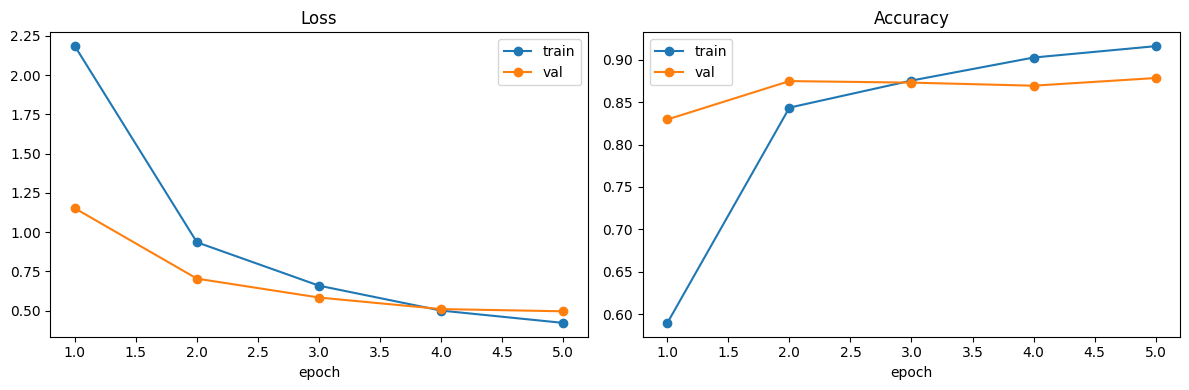

In [12]:
import matplotlib.pyplot as plt

epochs = range(1, num_epochs + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(epochs, history["train_loss"], marker="o", label="train")
ax1.plot(epochs, history["val_loss"], marker="o", label="va l")
ax1.set_title("Loss"); ax1.set_xlabel("epoch"); ax1.legend()

ax2.plot(epochs, history["train_acc"], marker="o", label="train")
ax2.plot(epochs, history["val_acc"], marker="o", label="val")
ax2.set_title("Accuracy"); ax2.set_xlabel("epoch"); ax2.legend()

plt.tight_layout()
plt.savefig(artifacts_dir / "baseline_curves.png", dpi=120)   # for the README later
plt.show()

### Learning curves
- Both losses falling together → learning; train ↓ while val ↑ → overfitting; both flat and high → underfitting.
- With only 47k trainable weights, expect little overfitting. Compare on Wednesday, when ~4M weights get unfrozen.
- My observation: _(write what you see)_

In [13]:
best_model = build_model("efficientnet_b0", num_classes=37, freeze=True).to(device)
best_model.load_state_dict(torch.load(ckpt_path, map_location=device))

_, reloaded_acc = evaluate(best_model, val_loader, loss_fn, device)
print("best during training:", round(best_val_acc, 4), " reloaded:", round(reloaded_acc, 4))
assert abs(reloaded_acc - best_val_acc) < 0.002
print("✓ Checkpoint reloads correctly. Day 2 done!")

best during training: 0.8786  reloaded: 0.8786
✓ Checkpoint reloads correctly. Day 2 done!
